# Step 03: patient splits

Builds the train/validation/test split, the cross-validation folds and the cross-hospital splits, all by patient, and checks them.

## Setup

Imports, paths and helpers.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import StratifiedGroupKFold, train_test_split

SEED = 42

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:.3f}".format)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 12, "axes.labelsize": 10, "legend.frameon": False})

COL_SEPTIC, COL_CONTROL = "#d1495b", "#2e86ab"
COL_A, COL_B = "#edae49", "#6a994e"
COL_ALL = "#6c757d"


def find_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for folder in [start, *start.parents]:
        if (folder / "dataset").is_dir():
            return folder
    raise FileNotFoundError(f"no folder containing a 'dataset' directory above {start}")


ROOT = find_root()
PROC = ROOT / "data" / "processed"
SPLITS = PROC / "splits"
TAB = ROOT / "results" / "tables"
FIG = ROOT / "results" / "figures"
for folder in (SPLITS, TAB, FIG):
    folder.mkdir(parents=True, exist_ok=True)

SUMMARY = []
SAVED = []


def log(text=""):
    print(text)
    SUMMARY.append(str(text))


def check(label, ok, detail=""):
    log(f"[{'PASS' if ok else 'FAIL'}] {label}" + (f" ({detail})" if detail else ""))


def fmt(x):
    return f"{x:,}" if isinstance(x, (int, np.integer)) else f"{x:,.2f}"


def expect(label, observed, expected, tol=0):
    check(label, abs(observed - expected) <= tol, f"observed {fmt(observed)}, expected {fmt(expected)}")


def save_fig(name, top=None):
    plt.tight_layout(rect=(0, 0, 1, top) if top else None)
    path = FIG / name
    plt.savefig(path, dpi=150, bbox_inches="tight")
    SAVED.append(path)
    plt.show()
    plt.close("all")


def save_table(table, name, **kwargs):
    path = TAB / name
    table.to_csv(path, **kwargs)
    SAVED.append(path)


log(f"project root: {ROOT.name}")

project root: Sepsis_ml


## Patient table

Loaded and compared with the numbers from the audit.

In [2]:
patients = pd.read_csv(PROC / "patient_table.csv", dtype={"patient_id": "string", "hospital": "string"})
log(f"patient table shape: {patients.shape}")

by_hosp = patients.groupby("hospital")
positive_pct = by_hosp["n_positive_rows"].sum() / by_hosp["n_rows"].sum() * 100
n_pat = len(patients)
n_sep = int(patients["ever_septic"].sum())

log("known facts versus observed")
check("patient_id unique", patients["patient_id"].is_unique, f"{int(patients['patient_id'].duplicated().sum())} duplicates")
check("ordered hospital A then B, ids sorted within hospital",
      patients["hospital"].is_monotonic_increasing and bool(by_hosp["patient_id"].apply(lambda s: s.is_monotonic_increasing).all()))
expect("patients", n_pat, 40336)
expect("patients, hospital A", int((patients["hospital"] == "A").sum()), 20336)
expect("patients, hospital B", int((patients["hospital"] == "B").sum()), 20000)
expect("septic patients", n_sep, 2932)
expect("septic rate (%)", n_sep / n_pat * 100, 7.27, tol=0.01)
expect("septic patients, A", int(by_hosp["ever_septic"].sum()["A"]), 1790)
expect("septic patients, B", int(by_hosp["ever_septic"].sum()["B"]), 1142)
expect("septic rate A (%)", by_hosp["ever_septic"].mean()["A"] * 100, 8.80, tol=0.01)
expect("septic rate B (%)", by_hosp["ever_septic"].mean()["B"] * 100, 5.71, tol=0.01)
expect("rows", int(patients["n_rows"].sum()), 1552210)
expect("positive rows", int(patients["n_positive_rows"].sum()), 27916)
expect("positive rows (%)", patients["n_positive_rows"].sum() / patients["n_rows"].sum() * 100, 1.80, tol=0.01)
expect("positive rows A (%)", positive_pct["A"], 2.17, tol=0.01)
expect("positive rows B (%)", positive_pct["B"], 1.41, tol=0.01)
expect("median stay (rows)", float(patients["n_rows"].median()), 38)
expect("stays under 24 rows (%)", (patients["n_rows"] < 24).mean() * 100, 23.99, tol=0.01)
expect("septic patients labelled 1 in first row", int((patients["first_positive_hour"] == 0).sum()), 426)
max_pos = int(patients.loc[patients["ever_septic"], "n_positive_rows"].max())
check("no septic patient has more than 10 positive rows", max_pos <= 10, f"max {max_pos}")

suffix = patients["ever_septic"].map({True: "septic", False: "non"})
patients["strata"] = patients["hospital"] + "_" + suffix
log("stratum sizes")
log(patients["strata"].value_counts().sort_index().to_string())
patients.head(3)

patient table shape: (40336, 6)
known facts versus observed
[PASS] patient_id unique (0 duplicates)
[PASS] ordered hospital A then B, ids sorted within hospital
[PASS] patients (observed 40,336, expected 40,336)
[PASS] patients, hospital A (observed 20,336, expected 20,336)
[PASS] patients, hospital B (observed 20,000, expected 20,000)
[PASS] septic patients (observed 2,932, expected 2,932)
[PASS] septic rate (%) (observed 7.27, expected 7.27)
[PASS] septic patients, A (observed 1,790, expected 1,790)
[PASS] septic patients, B (observed 1,142, expected 1,142)
[PASS] septic rate A (%) (observed 8.80, expected 8.80)
[PASS] septic rate B (%) (observed 5.71, expected 5.71)
[PASS] rows (observed 1,552,210, expected 1,552,210)
[PASS] positive rows (observed 27,916, expected 27,916)
[PASS] positive rows (%) (observed 1.80, expected 1.80)
[PASS] positive rows A (%) (observed 2.17, expected 2.17)
[PASS] positive rows B (%) (observed 1.41, expected 1.41)
[PASS] median stay (rows) (observed 38.00

,patient_id,hospital,n_rows,ever_septic,first_positive_hour,n_positive_rows,strata
0,p000001,A,54,False,NaN,0,A_non
1,p000002,A,23,False,NaN,0,A_non
2,p000003,A,48,False,NaN,0,A_non


## ICULOS offset

First ICULOS per patient, read from the five parquet columns only.

In [3]:
rows = pd.read_parquet(PROC / "sepsis_master.parquet", columns=["patient_id", "hospital", "hour", "ICULOS", "SepsisLabel"])
log(f"parquet rows: {len(rows):,}, memory {rows.memory_usage(deep=True).sum() / 1e6:.0f} MB")
expect("parquet rows", len(rows), 1552210)
expect("parquet positive rows", int((rows["SepsisLabel"] == 1).sum()), 27916)

row_counts = patients["patient_id"].map(rows["patient_id"].value_counts())
n_count_mismatch = int((row_counts != patients["n_rows"]).sum())
check("rows per patient in parquet match the patient table", n_count_mismatch == 0, f"{n_count_mismatch:,} patients differ")

first_iculos = rows.loc[rows["hour"] == 0].set_index("patient_id")["ICULOS"]
check("one hour-0 row per patient", first_iculos.index.is_unique and len(first_iculos) == n_pat, f"{len(first_iculos):,} rows")
patients["first_iculos"] = patients["patient_id"].map(first_iculos)
check("first ICULOS found for every patient", bool(patients["first_iculos"].notna().all()))
if patients["first_iculos"].notna().all():
    patients["first_iculos"] = patients["first_iculos"].astype("int32")

late = patients["first_iculos"] > 1
log(f"patients with first ICULOS > 1: {int(late.sum()):,} ({late.mean() * 100:.2f}%)")


def late_share(key):
    grp = late.groupby(patients[key])
    return pd.DataFrame({"patients": grp.size(), "first_iculos_gt1": grp.sum(), "pct": grp.mean() * 100})


log("by hospital")
log(late_share("hospital").round(2).to_string())
log("by septic status")
log(late_share("ever_septic").round(2).to_string())
log("first ICULOS of those patients")
log(patients.loc[late, "first_iculos"].describe(percentiles=[0.25, 0.5, 0.75]).loc[["min", "25%", "50%", "75%", "max"]].to_string())

offset = rows["patient_id"].map(first_iculos)
n_offset_bad = int((rows["ICULOS"] != rows["hour"] + offset).sum())
check("ICULOS == hour + first ICULOS for every row", n_offset_bad == 0, f"{n_offset_bad:,} violating rows")
n_plus1 = int((rows["ICULOS"] != rows["hour"] + 1).sum())
expect("rows with ICULOS != hour + 1", n_plus1, 329595)
del offset

parquet rows: 1,552,210, memory 48 MB
[PASS] parquet rows (observed 1,552,210, expected 1,552,210)
[PASS] parquet positive rows (observed 27,916, expected 27,916)
[PASS] rows per patient in parquet match the patient table (0 patients differ)
[PASS] one hour-0 row per patient (40,336 rows)
[PASS] first ICULOS found for every patient
patients with first ICULOS > 1: 8,793 (21.80%)
by hospital
          patients  first_iculos_gt1    pct
hospital                                   
A            20336              7497 36.870
B            20000              1296  6.480
by septic status
             patients  first_iculos_gt1    pct
ever_septic                                   
False           37404              8136 21.750
True             2932               657 22.410
first ICULOS of those patients
min     2.000
25%     2.000
50%     3.000
75%     4.000
max   304.000
[PASS] ICULOS == hour + first ICULOS for every row (0 violating rows)
[PASS] rows with ICULOS != hour + 1 (observed 329,595, 

## Train, validation and test split

70/15/15 by patient, stratified on hospital and septic status.

In [4]:
train_idx, temp_idx = train_test_split(patients.index, test_size=0.30, stratify=patients["strata"], random_state=SEED)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.50, stratify=patients.loc[temp_idx, "strata"], random_state=SEED)

patients["split"] = "train"
patients.loc[val_idx, "split"] = "val"
patients.loc[test_idx, "split"] = "test"
log("patients per split: " + ", ".join(f"{k} {v:,}" for k, v in patients["split"].value_counts().reindex(["train", "val", "test"]).items()))

patients per split: train 28,235, val 6,050, test 6,051


## Cross-validation folds

Five folds on train and validation patients; test patients get -1.

In [5]:
trainval = patients.loc[patients["split"] != "test"]
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

patients["cv_fold"] = -1
for fold, (_, val_pos) in enumerate(sgkf.split(np.zeros(len(trainval)), trainval["strata"], groups=trainval["patient_id"])):
    patients.loc[trainval.index[val_pos], "cv_fold"] = fold

log("validation patients per fold: " + ", ".join(f"{k} {v:,}" for k, v in patients.loc[patients["cv_fold"] >= 0, "cv_fold"].value_counts().sort_index().items()))
log(f"test patients with cv_fold = -1: {int((patients.loc[patients['split'] == 'test', 'cv_fold'] == -1).sum()):,}")

validation patients per fold: 0 6,857, 1 6,857, 2 6,857, 3 6,857, 4 6,857
test patients with cv_fold = -1: 6,051


## Cross-hospital splits

Train on 85% of one hospital, validate on the rest, test on the other hospital.

In [6]:
for src, dst in [("A", "B"), ("B", "A")]:
    src_idx = patients.index[patients["hospital"] == src]
    xh_train, xh_val = train_test_split(src_idx, test_size=0.15, stratify=patients.loc[src_idx, "ever_septic"], random_state=SEED)
    col = f"xh_{src}_to_{dst}"
    patients[col] = "test"
    patients.loc[xh_train, col] = "train"
    patients.loc[xh_val, col] = "val"

    tbl = patients.groupby(col)["ever_septic"].agg(patients="size", septic_pct="mean")
    tbl["septic_pct"] = tbl["septic_pct"] * 100
    log(f"{src} -> {dst}")
    log(tbl.reindex(["train", "val", "test"]).round(2).to_string())

A -> B
           patients  septic_pct
xh_A_to_B                      
train         17285       8.800
val            3051       8.820
test          20000       5.710
B -> A
           patients  septic_pct
xh_B_to_A                      
train         17000       5.710
val            3000       5.700
test          20336       8.800


## Save

Split table and plain id lists.

In [7]:
out_cols = ["patient_id", "hospital", "ever_septic", "n_rows", "first_positive_hour", "n_positive_rows", "first_iculos",
            "strata", "split", "cv_fold", "xh_A_to_B", "xh_B_to_A"]
splits_path = PROC / "patient_splits.csv"
patients[out_cols].to_csv(splits_path, index=False)
SAVED.append(splits_path)

for name in ("train", "val", "test"):
    path = SPLITS / f"{name}_ids.txt"
    path.write_text("\n".join(patients.loc[patients["split"] == name, "patient_id"]) + "\n")
    SAVED.append(path)
    log(f"{path.relative_to(ROOT)}: {int((patients['split'] == name).sum()):,} ids")

data/processed/splits/train_ids.txt: 28,235 ids
data/processed/splits/val_ids.txt: 6,050 ids
data/processed/splits/test_ids.txt: 6,051 ids


## Verification

Checks run on the saved files, then on the parquet rows.

In [8]:
ids = {name: set((SPLITS / f"{name}_ids.txt").read_text().split()) for name in ("train", "val", "test")}
saved = pd.read_csv(splits_path, dtype={"patient_id": "string", "hospital": "string"})
all_ids = set(saved["patient_id"])

check("patient_id unique in the patient table", bool(patients["patient_id"].is_unique))
check("saved split file has one row per patient", len(saved) == n_pat == len(all_ids), f"{len(saved):,} rows")
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    check(f"{a} and {b} are disjoint", len(ids[a] & ids[b]) == 0, f"{len(ids[a] & ids[b])} shared")
check("union of the three splits equals all patients", ids["train"] | ids["val"] | ids["test"] == all_ids,
      f"{len(ids['train'] | ids['val'] | ids['test']):,} of {len(all_ids):,}")
check("id lists match the split column", all(ids[n] == set(saved.loc[saved["split"] == n, "patient_id"]) for n in ids))

trainval_ids = ids["train"] | ids["val"]
fold_ids = {f: set(saved.loc[saved["cv_fold"] == f, "patient_id"]) for f in range(5)}
times_in_val = pd.Series(0, index=sorted(trainval_ids))
for f, members in fold_ids.items():
    times_in_val.loc[sorted(members & trainval_ids)] += 1
check("every train+val patient is in the validation part of exactly one fold", bool((times_in_val == 1).all()),
      f"{int((times_in_val != 1).sum())} patients not exactly once")
check("fold validation sets contain only train+val patients", all(m <= trainval_ids for m in fold_ids.values()))
check("test patients are in no fold", set(saved.loc[saved["cv_fold"] == -1, "patient_id"]) == ids["test"])
for f, members in fold_ids.items():
    fold_train = trainval_ids - members
    check(f"fold {f}: training and validation parts share no patient", len(fold_train & members) == 0,
          f"train {len(fold_train):,}, val {len(members):,}")

for src, dst in [("A", "B"), ("B", "A")]:
    col = saved[f"xh_{src}_to_{dst}"]
    xh = {k: set(saved.loc[col == k, "patient_id"]) for k in ("train", "val", "test")}
    src_ids = set(saved.loc[saved["hospital"] == src, "patient_id"])
    dst_ids = set(saved.loc[saved["hospital"] == dst, "patient_id"])
    disjoint = not (xh["train"] & xh["val"] or xh["train"] & xh["test"] or xh["val"] & xh["test"])
    check(f"{src}->{dst}: train, val and test are disjoint", disjoint)
    check(f"{src}->{dst}: test is exactly hospital {dst}", xh["test"] == dst_ids, f"{len(xh['test']):,} patients")
    check(f"{src}->{dst}: train and val are exactly hospital {src}", (xh["train"] | xh["val"]) == src_ids,
          f"train {len(xh['train']):,}, val {len(xh['val']):,}")

[PASS] patient_id unique in the patient table
[PASS] saved split file has one row per patient (40,336 rows)
[PASS] train and val are disjoint (0 shared)
[PASS] train and test are disjoint (0 shared)
[PASS] val and test are disjoint (0 shared)
[PASS] union of the three splits equals all patients (40,336 of 40,336)
[PASS] id lists match the split column
[PASS] every train+val patient is in the validation part of exactly one fold (0 patients not exactly once)
[PASS] fold validation sets contain only train+val patients
[PASS] test patients are in no fold
[PASS] fold 0: training and validation parts share no patient (train 27,428, val 6,857)
[PASS] fold 1: training and validation parts share no patient (train 27,428, val 6,857)
[PASS] fold 2: training and validation parts share no patient (train 27,428, val 6,857)
[PASS] fold 3: training and validation parts share no patient (train 27,428, val 6,857)
[PASS] fold 4: training and validation parts share no patient (train 27,428, val 6,857)
[PA

In [9]:
split_of = {**dict.fromkeys(ids["train"], "train"), **dict.fromkeys(ids["val"], "val"), **dict.fromkeys(ids["test"], "test")}
row_split = rows["patient_id"].map(split_of)
check("every parquet row belongs to a split", bool(row_split.notna().all()), f"{int(row_split.isna().sum()):,} rows without split")

rows_per_split = row_split.value_counts().reindex(["train", "val", "test"])
log("rows per split: " + ", ".join(f"{k} {v:,}" for k, v in rows_per_split.items()))
expect("rows per split sum to the total", int(rows_per_split.sum()), 1552210)
table_rows = patients.groupby("split")["n_rows"].sum().reindex(["train", "val", "test"])
check("row counts per split match n_rows in the patient table", bool((rows_per_split.to_numpy() == table_rows.to_numpy()).all()))

trainval_rows = rows["patient_id"].isin(trainval_ids)
leak = int(rows.loc[trainval_rows, "patient_id"].isin(ids["test"]).sum())
check("no test patient_id in any train or val row", leak == 0, f"{leak:,} rows")

[PASS] every parquet row belongs to a split (0 rows without split)
rows per split: train 1,085,958, val 234,037, test 232,215
[PASS] rows per split sum to the total (observed 1,552,210, expected 1,552,210)
[PASS] row counts per split match n_rows in the patient table
[PASS] no test patient_id in any train or val row (0 rows)


## Split summary

Counts and rates per split, from the patient table.

In [10]:
overall_rate = patients["ever_septic"].mean() * 100
overall_share_a = (patients["hospital"] == "A").mean() * 100
overall_share_b = 100 - overall_share_a


def summarise(sub):
    septic = sub.loc[sub["ever_septic"]]
    return {
        "patients": len(sub),
        "rows": int(sub["n_rows"].sum()),
        "patients_share_pct": len(sub) / n_pat * 100,
        "septic_patients": len(septic),
        "septic_pct": len(septic) / len(sub) * 100,
        "positive_rows": int(sub["n_positive_rows"].sum()),
        "positive_rows_pct": sub["n_positive_rows"].sum() / sub["n_rows"].sum() * 100,
        "hospital_A_pct": (sub["hospital"] == "A").mean() * 100,
        "hospital_B_pct": (sub["hospital"] == "B").mean() * 100,
        "median_stay_rows": sub["n_rows"].median(),
        "stays_under_24_pct": (sub["n_rows"] < 24).mean() * 100,
        "median_first_positive_hour": septic["first_positive_hour"].median(),
        "septic_labelled_in_first_row": int((septic["first_positive_hour"] == 0).sum()),
    }


summary_rows = {name: summarise(patients.loc[patients["split"] == name]) for name in ("train", "val", "test")}
summary_rows["all"] = summarise(patients)
split_summary = pd.DataFrame.from_dict(summary_rows, orient="index").rename_axis("split")
save_table(split_summary.round(3), "split_summary.csv")
log(split_summary.round(2).T.to_string())

for name in ("train", "val", "test"):
    s = split_summary.loc[name]
    check(f"{name}: septic % within 0.3 points of {overall_rate:.2f}%", abs(s["septic_pct"] - overall_rate) <= 0.3,
          f"{s['septic_pct']:.2f}%")
    check(f"{name}: hospital shares within 0.5 points of {overall_share_a:.2f}% / {overall_share_b:.2f}%",
          abs(s["hospital_A_pct"] - overall_share_a) <= 0.5 and abs(s["hospital_B_pct"] - overall_share_b) <= 0.5,
          f"A {s['hospital_A_pct']:.2f}%, B {s['hospital_B_pct']:.2f}%")
split_summary.round(2)

split                              train        val       test         all
patients                       28235.000   6050.000   6051.000   40336.000
rows                         1085958.000 234037.000 232215.000 1552210.000
patients_share_pct                70.000     15.000     15.000     100.000
septic_patients                 2052.000    440.000    440.000    2932.000
septic_pct                         7.270      7.270      7.270       7.270
positive_rows                  19530.000   4183.000   4203.000   27916.000
positive_rows_pct                  1.800      1.790      1.810       1.800
hospital_A_pct                    50.420     50.410     50.420      50.420
hospital_B_pct                    49.580     49.590     49.580      49.580
median_stay_rows                  39.000     39.000     38.000      38.000
stays_under_24_pct                24.180     23.390     23.680      23.990
median_first_positive_hour        27.000     29.500     28.500      28.000
septic_labelled_in_first_

,patients,rows,patients_share_pct,septic_patients,septic_pct,positive_rows,positive_rows_pct,hospital_A_pct,hospital_B_pct,median_stay_rows,stays_under_24_pct,median_first_positive_hour,septic_labelled_in_first_row
split,,,,,,,,,,,,,
train,28235,1085958,70.000,2052,7.270,19530,1.800,50.420,49.580,39.000,24.180,27.000,298
val,6050,234037,15.000,440,7.270,4183,1.790,50.410,49.590,39.000,23.390,29.500,65
test,6051,232215,15.000,440,7.270,4203,1.810,50.420,49.580,38.000,23.680,28.500,63
all,40336,1552210,100.000,2932,7.270,27916,1.800,50.420,49.580,38.000,23.990,28.000,426


## Fold summary

Validation and training parts of each fold.

In [11]:
trainval = patients.loc[patients["split"] != "test"]
trainval_rate = trainval["ever_septic"].mean() * 100

fold_records = []
for fold in range(5):
    val_part = trainval.loc[trainval["cv_fold"] == fold]
    train_part = trainval.loc[trainval["cv_fold"] != fold]
    fold_records.append({
        "fold": fold,
        "val_patients": len(val_part),
        "val_septic": int(val_part["ever_septic"].sum()),
        "val_septic_pct": val_part["ever_septic"].mean() * 100,
        "val_hospital_A_pct": (val_part["hospital"] == "A").mean() * 100,
        "train_patients": len(train_part),
        "train_septic_pct": train_part["ever_septic"].mean() * 100,
    })
fold_summary = pd.DataFrame(fold_records).set_index("fold")
save_table(fold_summary.round(3), "cv_fold_summary.csv")
log(fold_summary.round(2).to_string())

log(f"train+val septic rate: {trainval_rate:.2f}%")
for fold, s in fold_summary.iterrows():
    ok = abs(s["val_septic_pct"] - trainval_rate) <= 0.5 and abs(s["train_septic_pct"] - trainval_rate) <= 0.5
    check(f"fold {fold}: septic % within 0.5 points of the train+val rate", ok,
          f"val {s['val_septic_pct']:.2f}%, train {s['train_septic_pct']:.2f}%")
fold_summary.round(2)

      val_patients  val_septic  val_septic_pct  val_hospital_A_pct  train_patients  train_septic_pct
fold                                                                                                
0             6857         498           7.260              50.420           27428             7.270
1             6857         499           7.280              50.420           27428             7.270
2             6857         499           7.280              50.420           27428             7.270
3             6857         498           7.260              50.420           27428             7.270
4             6857         498           7.260              50.420           27428             7.270
train+val septic rate: 7.27%
[PASS] fold 0: septic % within 0.5 points of the train+val rate (val 7.26%, train 7.27%)
[PASS] fold 1: septic % within 0.5 points of the train+val rate (val 7.28%, train 7.27%)
[PASS] fold 2: septic % within 0.5 points of the train+val rate (val 7.28%, train 7.27

,val_patients,val_septic,val_septic_pct,val_hospital_A_pct,train_patients,train_septic_pct
fold,,,,,,
0,6857,498,7.260,50.420,27428,7.270
1,6857,499,7.280,50.420,27428,7.270
2,6857,499,7.280,50.420,27428,7.270
3,6857,498,7.260,50.420,27428,7.270
4,6857,498,7.260,50.420,27428,7.270


## Figure

Composition of the splits and of the validation parts of the folds.

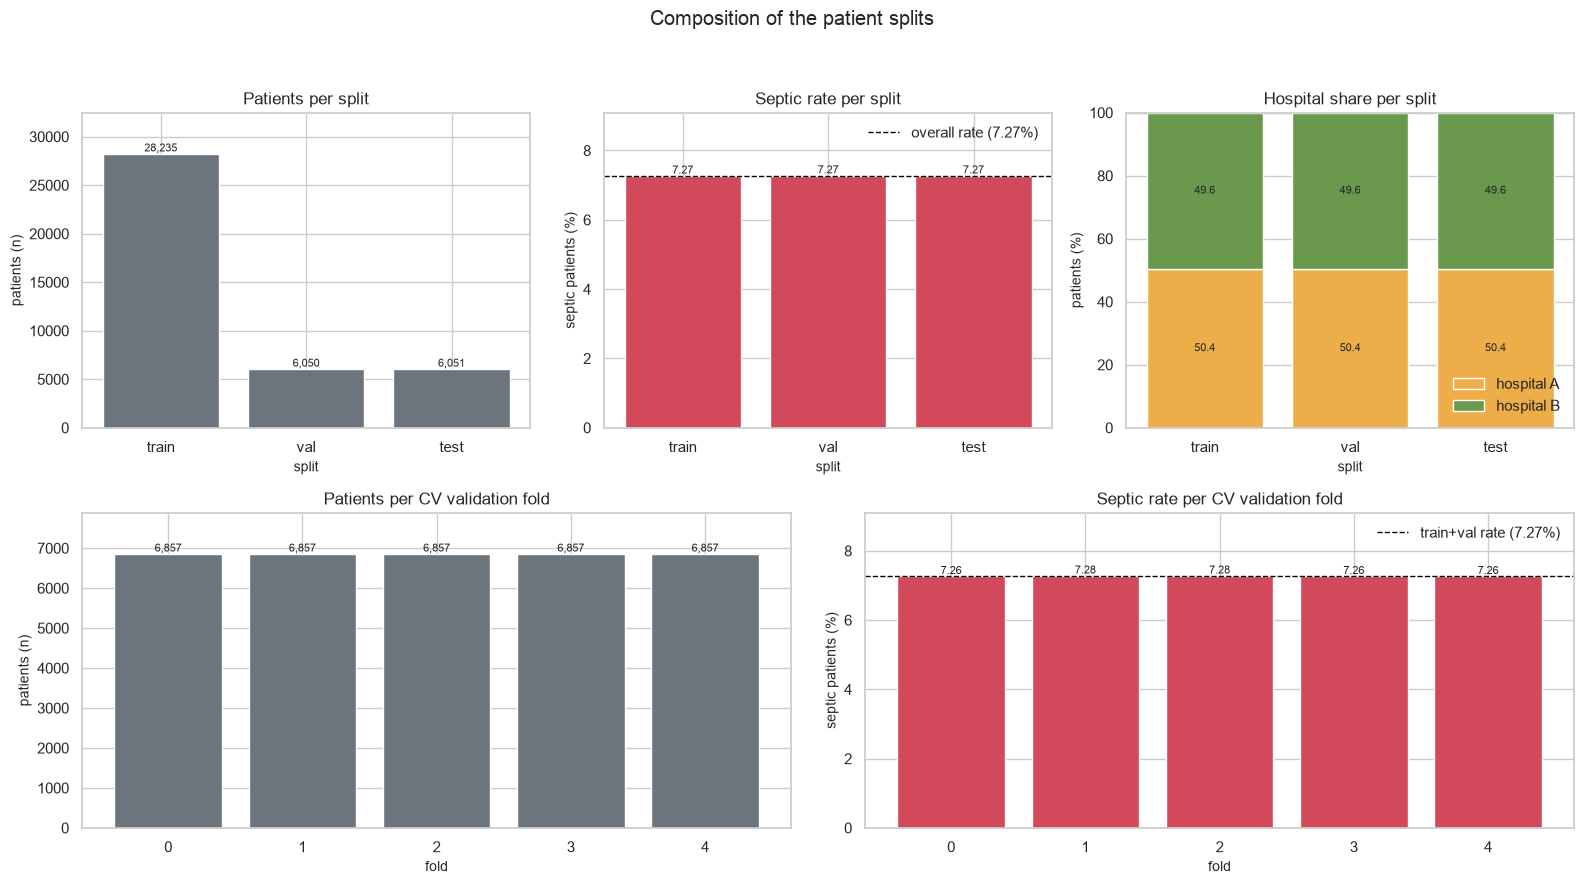

In [12]:
def bar_counts(ax, labels, values, title, xlabel):
    bars = ax.bar(labels, values, color=COL_ALL)
    ax.bar_label(bars, labels=[f"{v:,.0f}" for v in values], fontsize=8)
    ax.set(title=title, xlabel=xlabel, ylabel="patients (n)", ylim=(0, max(values) * 1.15))


def bar_rates(ax, labels, values, ref, ref_label, title, xlabel):
    bars = ax.bar(labels, values, color=COL_SEPTIC)
    ax.bar_label(bars, labels=[f"{v:.2f}" for v in values], fontsize=8)
    ax.axhline(ref, color="black", ls="--", lw=1, label=f"{ref_label} ({ref:.2f}%)")
    ax.set(title=title, xlabel=xlabel, ylabel="septic patients (%)", ylim=(0, max(values.max(), ref) * 1.25))
    ax.legend(loc="upper right")


def bar_hospitals(ax, labels, share_a, title, xlabel):
    ax.bar(labels, share_a, color=COL_A, label="hospital A")
    ax.bar(labels, 100 - share_a, bottom=share_a, color=COL_B, label="hospital B")
    for i, v in enumerate(share_a):
        ax.text(i, v / 2, f"{v:.1f}", ha="center", va="center", fontsize=8)
        ax.text(i, v + (100 - v) / 2, f"{100 - v:.1f}", ha="center", va="center", fontsize=8)
    ax.set(title=title, xlabel=xlabel, ylabel="patients (%)", ylim=(0, 100))
    ax.legend(loc="lower right")


names = ["train", "val", "test"]
fold_labels = [str(f) for f in fold_summary.index]

fig = plt.figure(figsize=(16, 9))
gs = fig.add_gridspec(2, 6)
bar_counts(fig.add_subplot(gs[0, 0:2]), names, split_summary.loc[names, "patients"].to_numpy(), "Patients per split", "split")
bar_rates(fig.add_subplot(gs[0, 2:4]), names, split_summary.loc[names, "septic_pct"].to_numpy(), overall_rate, "overall rate",
          "Septic rate per split", "split")
bar_hospitals(fig.add_subplot(gs[0, 4:6]), names, split_summary.loc[names, "hospital_A_pct"].to_numpy(), "Hospital share per split", "split")
bar_counts(fig.add_subplot(gs[1, 0:3]), fold_labels, fold_summary["val_patients"].to_numpy(), "Patients per CV validation fold", "fold")
bar_rates(fig.add_subplot(gs[1, 3:6]), fold_labels, fold_summary["val_septic_pct"].to_numpy(), trainval_rate, "train+val rate",
          "Septic rate per CV validation fold", "fold")
fig.suptitle("Composition of the patient splits")
save_fig("fig03_split_composition.png", top=0.95)

## Output files

In [13]:
summary_path = TAB.parent / "step03_summary.txt"

log("")
log("saved files")
for path in SAVED:
    status = f"{path.stat().st_size / 1e6:.2f} MB" if path.exists() else "MISSING"
    log(f"  {path.relative_to(ROOT)}  {status}")
log(f"  {summary_path.relative_to(ROOT)}  (this file)")

summary_path.write_text("\n".join(SUMMARY) + "\n")
print()
print(summary_path)


saved files
  data/processed/patient_splits.csv  1.97 MB
  data/processed/splits/train_ids.txt  0.23 MB
  data/processed/splits/val_ids.txt  0.05 MB
  data/processed/splits/test_ids.txt  0.05 MB
  results/tables/split_summary.csv  0.00 MB
  results/tables/cv_fold_summary.csv  0.00 MB
  results/figures/fig03_split_composition.png  0.13 MB
  results/step03_summary.txt  (this file)

/Users/harnoorkaur/Downloads/Sepsis_ml/results/step03_summary.txt
